# SliceGrouper Pipeline — Modular Research & Ground Truth Benchmarking
=======================================================================

A clean, production-oriented environment structured into dedicated `.py` modules:
1. **Data Loading**: Loads slide and mask, detects connected tissue components.
2. **Stage 1 (Tissue Core Identification)**: Separates tissue cores (A, B, C) via visual appearance.
3. **Stage 2 (Constellation Slice Matching)**: Groups fragments into physical slice sets ($S_0, S_1, S_2, ...$), **robust to tight/adjacent slice spacing** via constellation geometry and Hungarian assignment.
4. **Visualization**: Visual constellation overlay on slide and cross-slice alignment grid.
5. **Interactive Labeling Tool**: One-click ground truth annotation with auto-suggestions.
6. **Dataset Benchmarking**: Objective evaluation (ARI, NMI, Set Purity) across labeled slides.


---
## 1. Imports & Configuration

In [ ]:
%load_ext autoreload
%autoreload 2

import os, sys
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import config
from src import (
    load_tiff, load_mask, detect_components, ComponentData, Timer,
    ConstellationSliceMatcher, SliceSetResult,
    evaluate_slice_grouping, evaluate_dataset, load_ground_truth,
    SlideLabelerWidget,
    plot_constellation_slices_on_slide, plot_cross_slice_alignment_grid,
)
from src.io import load_slide
from src.color_features import extract_color_features_batch
from src.texture_features import extract_texture_features_batch
from src.clustering import cluster_components

cfg = config.Config()
print(f"Project root : {config.PROJECT_ROOT}")
print(f"Samples dir  : {config.SAMPLES_DIR}")
print(f"Active slide : {cfg.io.slide_path.name}")

---
## 2. Load Slide Image & Detect Components

In [ ]:
with Timer("Load slide and mask"):
    image, mask, components = load_slide(
        slide_path=cfg.io.slide_path,
        mask_path=cfg.io.mask_path,
        cfg=cfg.io,
    )

print(f"Slide shape     : {image.shape}")
print(f"Components found: {len(components)}")
for c in components:
    print(f"  Comp #{c.component_id}: area={c.area:,} px, centroid={c.centroid}")

---
## 3. Stage 1: Feature Extraction & Tissue Core Identification
Identifies distinct biopsy tissue cores ($A, B, C$) based on staining color and micro-texture.

In [ ]:
with Timer("Extract color and texture features"):
    color_feats = extract_color_features_batch(components, cfg.color)
    texture_feats = extract_texture_features_batch(components, cfg.texture)
    combined_feats = np.hstack([color_feats, texture_feats])

print(f"Feature matrix shape: {combined_feats.shape}")

# Cluster tissue types (e.g. agglomerative clustering into M cores)
n_cores_guess = max(2, min(4, len(components) // 2))
clust_res = cluster_components(combined_feats, method="agglomerative", n_clusters=n_cores_guess)
tissue_labels = clust_res.labels

print(f"Tissue clusters discovered: {set(tissue_labels)}")
for c, t in zip(components, tissue_labels):
    core_name = chr(65 + t) if t >= 0 else "Noise"
    print(f"  Comp #{c.component_id} -> Core {core_name}")

---
## 4. Stage 2: Constellation-Based Slice Set Grouping
Groups tissue cores into physical slice sets ($S_0, S_1, S_2, ...$).
**Robust to tightly packed slices** by leveraging relative invariant geometry and Hungarian matching.

In [ ]:
matcher = ConstellationSliceMatcher(max_spatial_tolerance_px=400.0)
slice_res = matcher.match(components, tissue_labels)

print(f"=== Slice Set Matching Summary ===")
print(f"Total Slices Detected (K): {slice_res.n_slices}")
print(f"Tissue Types per Slice (M): {slice_res.n_tissues}")
print(f"Estimated Shift Vector Δ : {slice_res.shift_vector}")

for s in slice_res.slice_sets:
    comp_str = ", ".join(f"Core {chr(65+k)}: #{cid}" for k, cid in s["components"].items())
    print(f"  Slice {s['slice_id']} ({s['n_components']} pieces) -> {comp_str}")

---
## 5. Visualizing Matched Slices & Alignment

In [ ]:
# Figure 1: Constellation overview on slide
fig_map = plot_constellation_slices_on_slide(image, components, slice_res)
plt.show()

# Figure 2: Cross-slice alignment grid
fig_grid = plot_cross_slice_alignment_grid(image, components, slice_res)
plt.show()

---
## 6. Szybkie Etykietowanie Datasetu (Kopiowanie Gotowego Formatu + Szybka Edycja)

**Jak to działa:**
1. Nad promptem pojawia się gotowy ciąg do skopiowania, np.: `0:(0,A), 1:(0,B), 2:(1,A), 3:(1,B)`.
2. **[ENTER]** ➔ Akceptuje sugestię i ładuje kolejny slajd.
3. **`f`** ➔ Oznacza cały slajd jako jedną całość (`Slice 0` bez cięcia) i przechodzi dalej.
4. **`z`** ➔ Wklejasz (Ctrl+V) skopiowany tekst, poprawiasz tylko błędną cyfrę/literę i klikasz Enter!
5. **`p`** ➔ Pomija slajd, **`q`** ➔ Kończy pętlę.

20:35:57 [INFO] SliceGrouper.io — Loading TIFF: 100816 Mallory.tiff (level=0)
20:35:57 [INFO] SliceGrouper.io — Loaded image: shape=(2048, 4096, 3), dtype=uint8
20:35:57 [INFO] SliceGrouper.io — Loading mask: 100816 Mallory_mask.tiff
20:35:57 [INFO] SliceGrouper.io — Mask loaded: shape=(2048, 4096), tissue_pixels=271,467, coverage=3.2%
20:35:57 [INFO] SliceGrouper.io — Running connected component analysis …
20:35:57 [INFO] SliceGrouper.io — Detected 2 components (min_area=6000px)
C:\Users\sitko\PycharmProjects\4Diagnosis_ComputerVision\SliceGrouperResearch\src\labeler.py:345: UserWarning: Glyph 9989 (\N{WHITE HEAVY CHECK MARK}) missing from font(s) DejaVu Sans.
  plt.tight_layout()


━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
📌 Slajd [22 / 108] (100% oznaczonych) | 100816 Mallory
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━


C:\Users\sitko\PycharmProjects\4Diagnosis_ComputerVision\venv_research\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 9989 (\N{WHITE HEAVY CHECK MARK}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


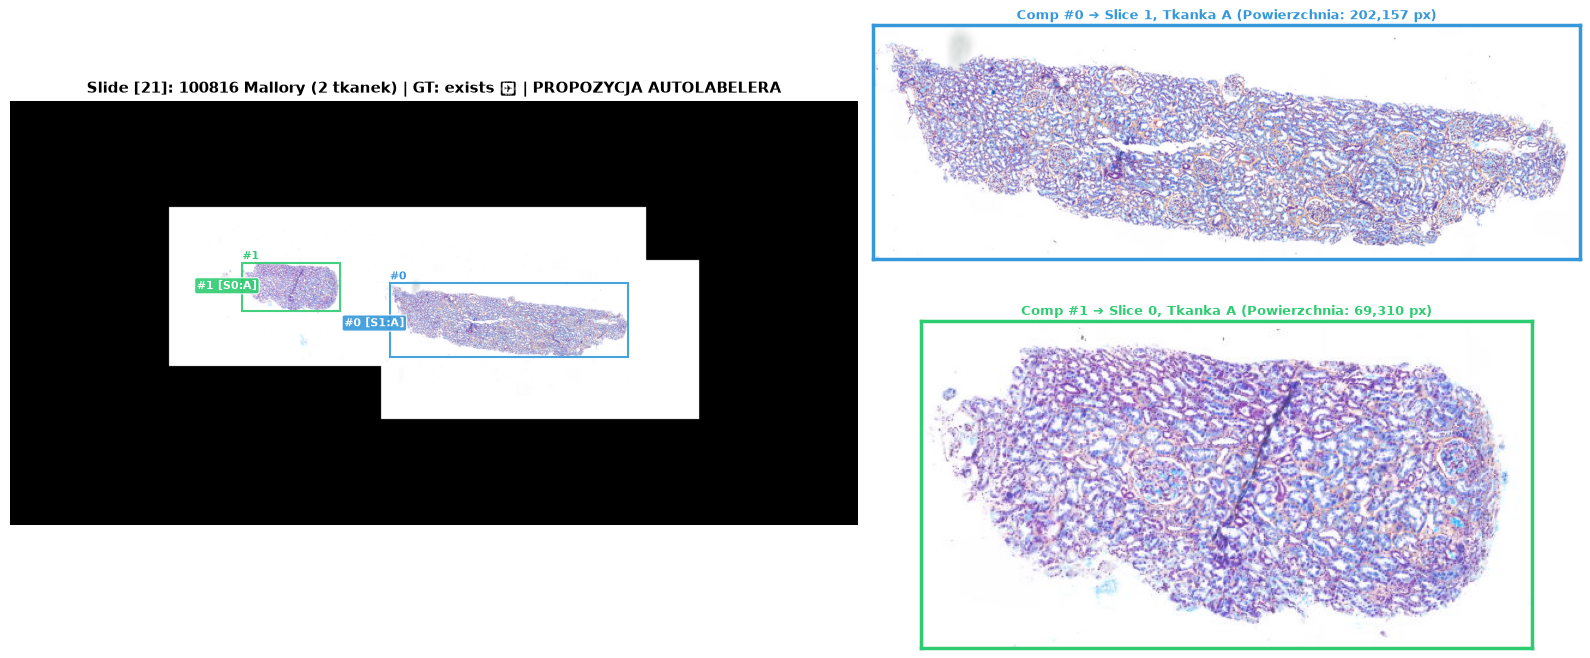

📋 Wykryte zestawy cięć (Slice Sets):
   • Slice 0: Comp #1 (A)
   • Slice 1: Comp #0 (A)

✂️  Gotowy tekst do skopiowania i edycji (Ctrl+C ➔ Ctrl+V):
   0:(1,A), 1:(0,A)
----------------------------------------------------------------------------


👉 [ENTER] = Zapisz sugestię  |  [f] = Całość (nie tnij)  |  [z] = Zmień  |  [p] = Pomiń  |  [q] = Wyjdź:  q


⏹️ Zakończono oznaczanie. Możesz wznowić w dowolnej chwili: labeler.review()


In [10]:
import importlib
import src.io
import src.labeler
importlib.reload(src.io)
importlib.reload(src.labeler)
from src.labeler import SlideLabelerWidget

labeler = SlideLabelerWidget()

# Uruchamia szybką pętlę ze skopiowanym tekstem gotowym do edycji:
labeler.review(20)


14:59:47 [INFO] SliceGrouper.io — Loading TIFF: 29464 Mallory.tiff (level=0)
14:59:47 [INFO] SliceGrouper.io — Loaded image: shape=(8192, 4096, 3), dtype=uint8
14:59:47 [INFO] SliceGrouper.io — Loading mask: 29464 Mallory_mask.tiff
14:59:48 [INFO] SliceGrouper.io — Mask loaded: shape=(8192, 4096), tissue_pixels=774,806, coverage=2.3%
14:59:48 [INFO] SliceGrouper.io — Running connected component analysis …
14:59:48 [INFO] SliceGrouper.io — Detected 11 components (min_area=500px)


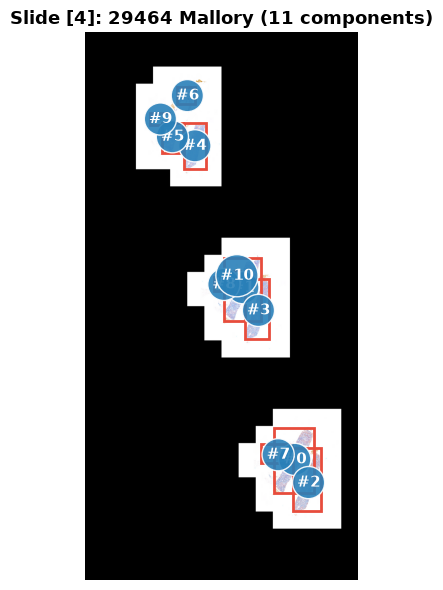

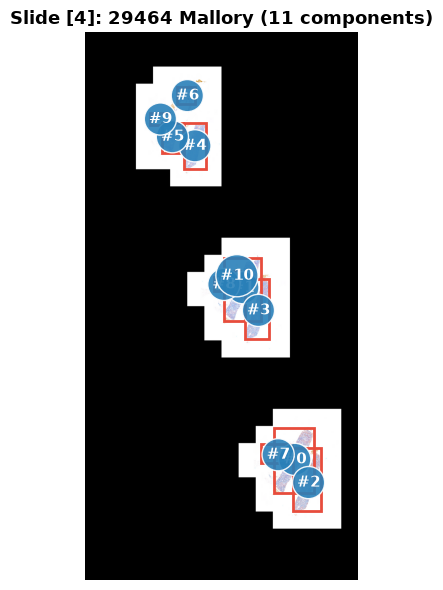

In [5]:
0:(2,A), 1:(0,A), 2:(1,A), 3:(2,C), 4:(1,C), 5:(0,C), 6:(1,B), 7:(2,B), 8:(0,B), 9:(0,C)
# Kompletny widok tabelaryczny ze wszystkimi slajdami (opcjonalny dashboard):
labeler.show()


---
## 7. Supervised Benchmarking across Dataset (ARI, NMI, Set Purity)
Runs the pipeline on all slides that have a `labels.json` and evaluates objective metrics.

In [ ]:
results = []
for slide_info in labeler.slides:
    gt = load_ground_truth(slide_info["labels_path"])
    if gt is None:
        continue

    img, msk, comps = load_slide(slide_info["tiff_path"], slide_info["mask_path"])
    c_feats = extract_color_features_batch(comps)
    t_feats = extract_texture_features_batch(comps)
    feats = np.hstack([c_feats, t_feats])

    n_tissues_gt = len(set(c["tissue_id"] for c in gt.get("components", [])))
    c_res = cluster_components(feats, method="agglomerative", n_clusters=max(1, n_tissues_gt))
    s_res = matcher.match(comps, c_res.labels)

    eval_res = evaluate_slice_grouping(
        pred_slice_labels=s_res.slice_labels,
        pred_tissue_labels=s_res.tissue_labels,
        ground_truth=gt,
        slide_name=slide_info["slide_name"],
    )
    results.append(eval_res)

if results:
    df_benchmark = evaluate_dataset(results)
    display(df_benchmark)
else:
    print("ℹ️ No ground-truth labels found yet. Use the labeling tool in Section 6 to annotate your slides!")